# Question 5

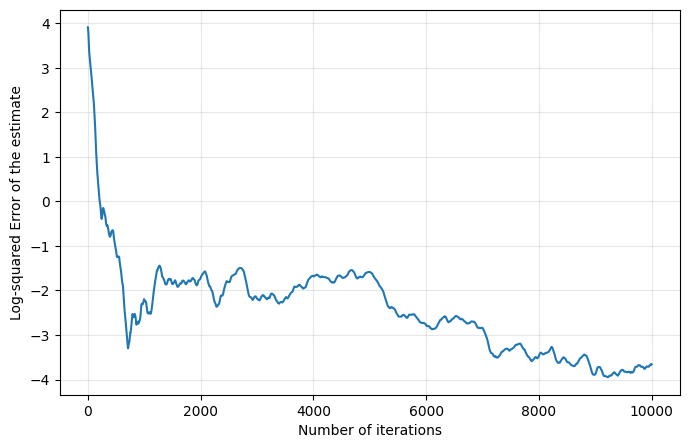

0.6914
0.558
0.4373
0.3143
0.1763


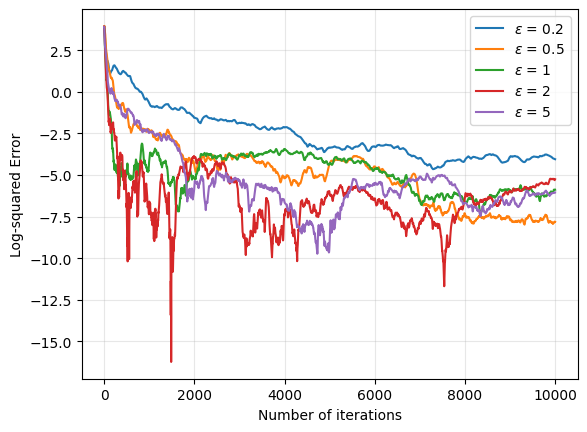

In [76]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt
from scipy.stats import multivariate_normal

np.random.seed(123)
# Problem 5

# (a) The Metropolis-Hasting algorithm

#Initial value for z
z_0 = np.array([5,5])
mean = np.array([0,0])
cov = np.array([[1,0.75],[0.75,1]])
Id = np.eye(2)
epsilon = 0.1

def f(z):
    return multivariate_normal.pdf(z,mean=mean, cov=cov) 

def MH(z, eps, n=10000):
    samples = np.zeros((n + 1, 2)) #Create a 2 column array with 0 everywhere, so it will store our estimates
    samples[0]=z
    accept_count = 0
    
    samples_mean = np.zeros((n + 1, 2))
    samples_mean[0] = z
    for i in range(n):
        z_new = multivariate_normal.rvs(mean=z,cov=eps * Id)
        alpha = min(1,f(z_new)/f(z) )
        u = np.random.uniform(0,1)
        if u <= alpha:
            z = z_new
            accept_count = accept_count+1
        samples[i+1]=z
        samples_mean[i+1]=np.mean(samples[:i+2],axis=0)
        
    return samples, samples_mean, accept_count/n

samples, samples_mean, accept_rate = MH(z=[5,5],n=10000,eps=0.1)

squared_error = np.sum((mean-samples_mean)**2,axis=1)

iterations = np.arange(len(squared_error))

plt.figure(figsize=(8, 5))
plt.plot(iterations[1:], np.log(squared_error[1:]))

plt.xlabel("Number of iterations")
plt.ylabel("Log-squared Error of the estimate")
plt.title("")
plt.grid(alpha=0.3)

plt.show()


# 5(b)

eps_list = [0.2,0.5,1,2,5]

for i in range(len(eps_list)):
    samples,samples_mean, accept_rate = MH(z=[5,5],eps=eps_list[i],n=10000)
    
    squared_error = squared_error = np.sum((mean-samples_mean)**2,axis=1)
    
    iterations = np.arange(len(squared_error))

    plt.plot(iterations[1:], np.log(squared_error[1:]),label=f"$\\epsilon$ = {eps_list[i]}")
    
    print(accept_rate) #[0.6914, 0.558, 0.4373, 0.3143, 0.1763]

plt.xlabel("Number of iterations")
plt.ylabel("Log-squared Error")
plt.title("")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


# Question 6

In [77]:
import numpy as np
import scipy.stats as stats
import matplotlib.pyplot as plt

np.random.seed(123)



def ising_density(x,A,beta):
    return np.exp(0.5 * beta * x.T @ A @ x)

def MH_ising(x,A,beta,N,T,chains):
    
    x = np.zeros((chains,N))
    Sx = np.zeros((T+1, chains))
    Hx = np.zeros((T+1, chains))
    
    
    #Initialization
    for i in range(chains):
        x[i] = np.random.choice([-1,1],size = N)
        
    Sx[0,:] = np.sum(x, axis=1)
    Hx[0,i] = -0.5 * x[i].T @ A @ x[i]
    
    #MH algorithm on each chain
    for i in range(T):
        for j in range(chains):
            
            #make a copy of the current state and create a proposal by fliping one sign
            x_new = x[j].copy()
            k = np.random.randint(0,N)
            x_new[k] *= -1
            
            # acceptance ratio
            alpha = min(1, ising_density(x_new,A,beta)/ising_density(x[j],A,beta)) 
            
            u = np.random.uniform(0,1)
            if u <= alpha:
                x[j] = x_new
            
            Sx[i+1,j] = np.sum(x[j])
            Hx[i+1,j] = -0.5 * x[j].T @ A @ x[j]
    
    S_mean = np.mean(Sx[1:,:], axis = 0)
    
    H_mean = np.mean(Hx[1:,:], axis = 0)
    
    B_hat = np.var(S_mean, ddof=1)
    
    W_hat = np.mean(np.var(Sx[1:, :], axis=0, ddof=1))
    
    R_hat = np.sqrt((T-1)/T + B_hat/ W_hat)
    
    
    
                
    return Sx, S_mean, H_mean, Hx, B_hat, W_hat, R_hat

 #MH_ising(x,A,beta,N,T,chains)


[ -2. -36.  20.   4.]
[-2.028  9.748  7.276 18.72 ]
[ 102.324  -79.652   39.516 -227.08 ]
[ 126. -520.  -72.  120.]
72.77423333333333
213.24377154308627
1.1572694120523375
2.930209797832561


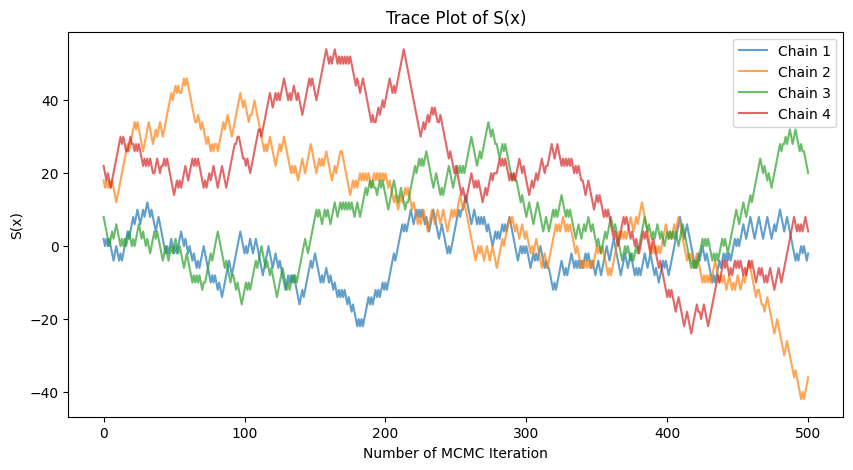

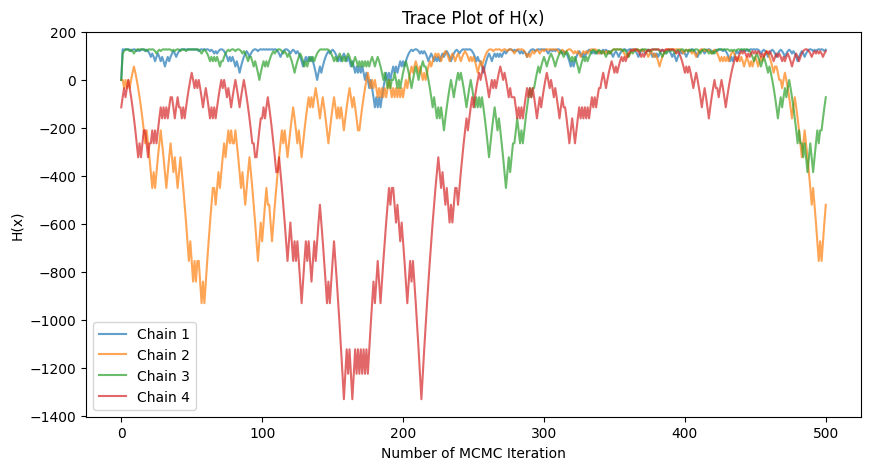

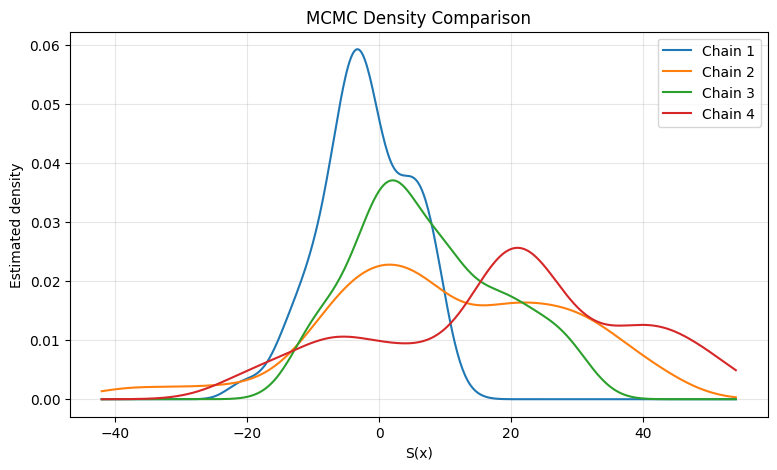

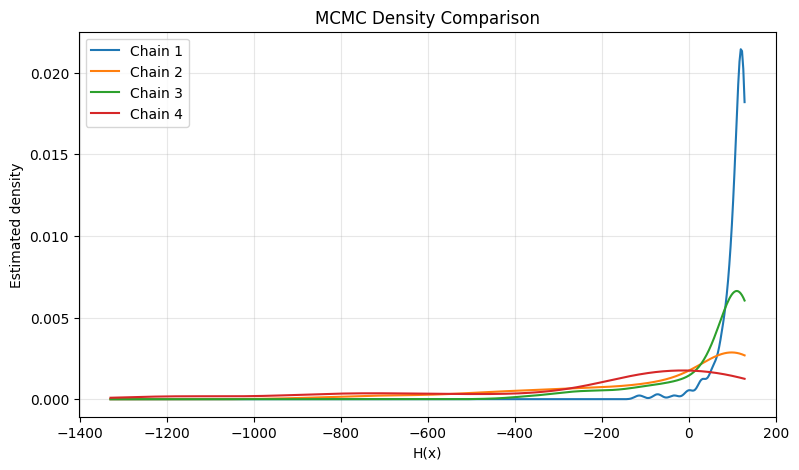

In [78]:

#iniial parameters. For the purpose of this project i will overwrite them.
N = 256
beta = 1/(4 * N)
A = np.ones((N,N)) - np.eye(N) # the diagonal is set to be 0.
chains = 4
T = 500

x = np.zeros((chains, N))

Sx_MH, S_mean_MH, H_mean_MH, Hx_MH, B_hat_MH, W_hat_MH, R_hat_MH = MH_ising(x,A,beta,N,T,chains)

print(Sx_MH[T])

print(S_mean_MH)

print(H_mean_MH)

print(Hx_MH[T])

print(B_hat_MH)

print(W_hat_MH)

print(R_hat_MH)

print(W_hat_MH/B_hat_MH)

#plotting the traceplot for S
plt.figure(figsize=(10, 5))

for j in range(chains):
    plt.plot(Sx_MH[:, j], label=f"Chain {j+1}", alpha=0.7)

plt.xlabel("Number of MCMC Iteration")
plt.ylabel("S(x)")
plt.title("Trace Plot of S(x)")
plt.legend()
plt.show()

# plotting the traceplot for H
plt.figure(figsize=(10, 5))

for j in range(chains):
    plt.plot(Hx_MH[:, j], label=f"Chain {j+1}", alpha=0.7)

plt.xlabel("Number of MCMC Iteration")
plt.ylabel("H(x)")
plt.title("Trace Plot of H(x)")
plt.legend()
plt.show()


#Density plot

MH_values = Sx_MH[1:,:].flatten()
kde_MH = stats.gaussian_kde(MH_values)
x_grid = np.linspace(-100, 100, 500)

plt.figure(figsize=(9, 5))

for j in range(chains):
    
    values = Sx_MH[1:,j]
    kde = stats.gaussian_kde(values)
    
    x_grid = np.linspace(np.min(Sx_MH), np.max(Sx_MH),500)
    plt.plot(x_grid, kde(x_grid),label=f"Chain {j+1}")

plt.xlabel("S(x)")
plt.ylabel("Estimated density")
plt.title("MCMC Density Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()

# density plot for H:
MH_values = Hx_MH[1:,:].flatten()
kde_MH = stats.gaussian_kde(MH_values)
x_grid = np.linspace(-100, 100, 500)

plt.figure(figsize=(9, 5))

for j in range(chains):
    
    values = Hx_MH[1:,j]
    kde = stats.gaussian_kde(values)
    
    x_grid = np.linspace(np.min(Hx_MH), np.max(Hx_MH),500)
    plt.plot(x_grid, kde(x_grid),label=f"Chain {j+1}")

plt.xlabel("H(x)")
plt.ylabel("Estimated density")
plt.title("MCMC Density Comparison")
plt.legend()
plt.grid(alpha=0.3)
plt.show()








[ -2.   6. -18.  14.]
[-0.068 -0.78  -0.372 -0.104]
0.10799333333333333
350.36818036072134
0.9991537560066729
3244.3500866786962


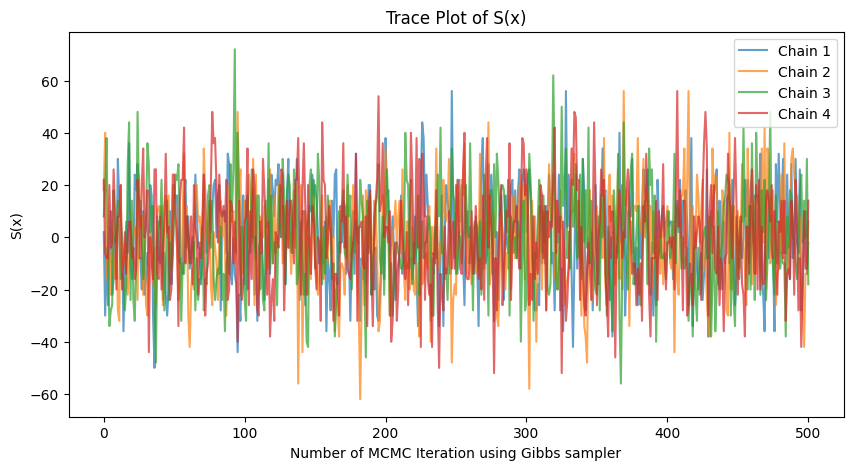

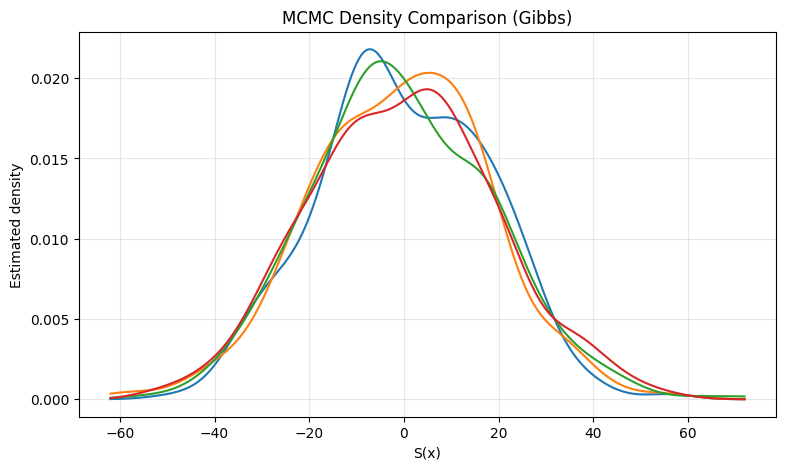

In [79]:
#Gibbs sampler
np.random.seed(123)

def ising_density(x,A,beta):
    return np.exp(0.5 * beta * x.T @ A @ x)


def Gibbs(x,A,beta,N,T,chains):
    
    # initialize the vector
    x = np.zeros((chains, N))
    Sx = np.zeros((T+1, chains))
    
    
    for i in range(chains):
        x[i] = np.random.choice([-1,1],size = N)
    
    Sx[0,:] = np.sum(x, axis=1)
    
    for i in range(T):
        for j in range(chains):
            x_new = x[j].copy()
            for k in range(N):
                h_k = A[k,:] @ x_new
                p_k = 1/ (1 + np.exp(-2 * beta * h_k))
                u_k = np.random.uniform(0,1)
                
                if u_k <= p_k:
                    x_new[k]=1
                else:
                    x_new[k]=-1
            
            x[j] = x_new
        
            Sx[i+1,j] = np.sum(x[j])
    
    S_mean = np.mean(Sx[1:,:], axis = 0)
         
    B_hat = np.var(S_mean, ddof=1)
        
    W_hat = np.mean(np.var(Sx[1:, :], axis=0, ddof=1))
        
    R_hat = np.sqrt((T-1)/T + B_hat/ W_hat)
            
    return Sx, S_mean, B_hat, W_hat, R_hat

Sx_G, S_mean_G, B_hat_G, W_hat_G, R_hat_G = Gibbs(x,A,beta,N,T,chains)
    
print(Sx_G[T])

print(S_mean_G)

print(B_hat_G)

print(W_hat_G)

print(R_hat_G)

print(W_hat_G/B_hat_G)

#plotting the traceplot for S
plt.figure(figsize=(10, 5))

for j in range(chains):
    plt.plot(Sx_G[:, j], label=f"Chain {j+1}", alpha=0.7)

plt.xlabel("Number of MCMC Iteration using Gibbs sampler")
plt.ylabel("S(x)")
plt.title("Trace Plot of S(x)")
plt.legend()
plt.show()
            
            
#Density plot

G_values = Sx_G[1:,:].flatten()
kde_G = stats.gaussian_kde(G_values)
x_grid = np.linspace(-100, 100, 500)

plt.figure(figsize=(9, 5))

for j in range(chains):
    
    values = Sx_G[1:,j]
    kde = stats.gaussian_kde(values)
    
    x_grid = np.linspace(np.min(Sx_G), np.max(Sx_G),500)
    plt.plot(x_grid, kde(x_grid),label=f"Chain {j+1}")

plt.xlabel("S(x)")
plt.ylabel("Estimated density")
plt.title("MCMC Density Comparison (Gibbs)")
#plt.legend()
plt.grid(alpha=0.3)
plt.show()    
            
    
    
    
    


